In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [3]:
setwd("/home/liuxuan/metadata/10-10/PRJNA863466/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,Collection_Date,⋯,LibrarySelection,LibrarySource,Organism,Platform,ReleaseDate,replicate,create_date,version,Sample.Name,SRA.Study
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<int>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,SRR20706832,AMPLICON,493,39346578,PRJNA863466,SAMN30048157,Metagenome or environmental,12345420,"HOSPITAL OF STOMATOLOGY, JILIN UNIVERSITY",2022,⋯,PCR,METAGENOMIC,human saliva metagenome,ILLUMINA,2022-08-08T00:00:00Z,replicate = biological replicate 10,2022-07-29T08:46:00Z,1,A10,SRP388727
2,SRR20706833,AMPLICON,493,39410958,PRJNA863466,SAMN30048156,Metagenome or environmental,12391795,"HOSPITAL OF STOMATOLOGY, JILIN UNIVERSITY",2022,⋯,PCR,METAGENOMIC,human saliva metagenome,ILLUMINA,2022-08-08T00:00:00Z,replicate = biological replicate 9,2022-07-29T08:46:00Z,1,A9,SRP388727
3,SRR20706834,AMPLICON,493,39454918,PRJNA863466,SAMN30048155,Metagenome or environmental,12429777,"HOSPITAL OF STOMATOLOGY, JILIN UNIVERSITY",2022,⋯,PCR,METAGENOMIC,human saliva metagenome,ILLUMINA,2022-08-08T00:00:00Z,replicate = biological replicate 8,2022-07-29T08:46:00Z,1,A8,SRP388727
4,SRR20706835,AMPLICON,493,39291928,PRJNA863466,SAMN30048154,Metagenome or environmental,12389802,"HOSPITAL OF STOMATOLOGY, JILIN UNIVERSITY",2022,⋯,PCR,METAGENOMIC,human saliva metagenome,ILLUMINA,2022-08-08T00:00:00Z,replicate = biological replicate 7,2022-07-29T08:46:00Z,1,A7,SRP388727
5,SRR20706836,AMPLICON,493,39510324,PRJNA863466,SAMN30048153,Metagenome or environmental,12444306,"HOSPITAL OF STOMATOLOGY, JILIN UNIVERSITY",2022,⋯,PCR,METAGENOMIC,human saliva metagenome,ILLUMINA,2022-08-08T00:00:00Z,replicate = biological replicate 6,2022-07-29T08:46:00Z,1,A6,SRP388727
6,SRR20706837,AMPLICON,493,39565546,PRJNA863466,SAMN30048152,Metagenome or environmental,12425006,"HOSPITAL OF STOMATOLOGY, JILIN UNIVERSITY",2022,⋯,PCR,METAGENOMIC,human saliva metagenome,ILLUMINA,2022-08-08T00:00:00Z,replicate = biological replicate 5,2022-07-29T08:46:00Z,1,A5,SRP388727


[1] "Run"                            "Assay.Type"                    
 [3] "AvgSpotLen"                     "Bases"                         
 [5] "BioProject"                     "BioSample"                     
 [7] "BioSampleModel"                 "Bytes"                         
 [9] "Center.Name"                    "Collection_Date"               
[11] "Consent"                        "DATASTORE.filetype"            
[13] "DATASTORE.provider"             "DATASTORE.region"              
[15] "Experiment"                     "geo_loc_name_country"          
[17] "geo_loc_name_country_continent" "geo_loc_name"                  
[19] "Instrument"                     "isolation_source"              
[21] "lat_lon"                        "Library.Name"                  
[23] "LibraryLayout"                  "LibrarySelection"              
[25] "LibrarySource"                  "Organism"                      
[27] "Platform"                       "ReleaseDate"                   
[29] "replicate"                      "create_date"                   
[31] "version"                        "Sample.Name"                   
[33] "SRA.Study"

In [4]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = 'V3-V4',
    Platform = initial_meta$Platform,
    Country = NA,
    Site = 'saliva',
    public_time = initial_meta$ReleaseDate,
    PCR_primers = 'F:ACTCCTACGGGAGGCAGCA; R: GGACTACHVGGGTWTCTAAT',
    title = "Saliva microbiome changes in thyroid cancer and thyroid nodules patients",
    Disease_study = "YES",
    Status = initial_meta$'isolation_source',
    matched_samples = 'NO')

In [5]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 38
[1] 38


In [6]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>,<chr>,<chr>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,PRJNA863466,SRR20706832,A10,NA,NA,NA,V3-V4,ILLUMINA,NA,saliva,2022-08-08T00:00:00Z,F:ACTCCTACGGGAGGCAGCA; R: GGACTACHVGGGTWTCTAAT,Saliva microbiome changes in thyroid cancer and thyroid nodules patients,YES,thyroid cancer patient,NO
2,PRJNA863466,SRR20706833,A9,NA,NA,NA,V3-V4,ILLUMINA,NA,saliva,2022-08-08T00:00:00Z,F:ACTCCTACGGGAGGCAGCA; R: GGACTACHVGGGTWTCTAAT,Saliva microbiome changes in thyroid cancer and thyroid nodules patients,YES,thyroid cancer patient,NO
3,PRJNA863466,SRR20706834,A8,NA,NA,NA,V3-V4,ILLUMINA,NA,saliva,2022-08-08T00:00:00Z,F:ACTCCTACGGGAGGCAGCA; R: GGACTACHVGGGTWTCTAAT,Saliva microbiome changes in thyroid cancer and thyroid nodules patients,YES,thyroid cancer patient,NO
4,PRJNA863466,SRR20706835,A7,NA,NA,NA,V3-V4,ILLUMINA,NA,saliva,2022-08-08T00:00:00Z,F:ACTCCTACGGGAGGCAGCA; R: GGACTACHVGGGTWTCTAAT,Saliva microbiome changes in thyroid cancer and thyroid nodules patients,YES,thyroid cancer patient,NO
5,PRJNA863466,SRR20706836,A6,NA,NA,NA,V3-V4,ILLUMINA,NA,saliva,2022-08-08T00:00:00Z,F:ACTCCTACGGGAGGCAGCA; R: GGACTACHVGGGTWTCTAAT,Saliva microbiome changes in thyroid cancer and thyroid nodules patients,YES,thyroid cancer patient,NO
6,PRJNA863466,SRR20706837,A5,NA,NA,NA,V3-V4,ILLUMINA,NA,saliva,2022-08-08T00:00:00Z,F:ACTCCTACGGGAGGCAGCA; R: GGACTACHVGGGTWTCTAAT,Saliva microbiome changes in thyroid cancer and thyroid nodules patients,YES,thyroid cancer patient,NO


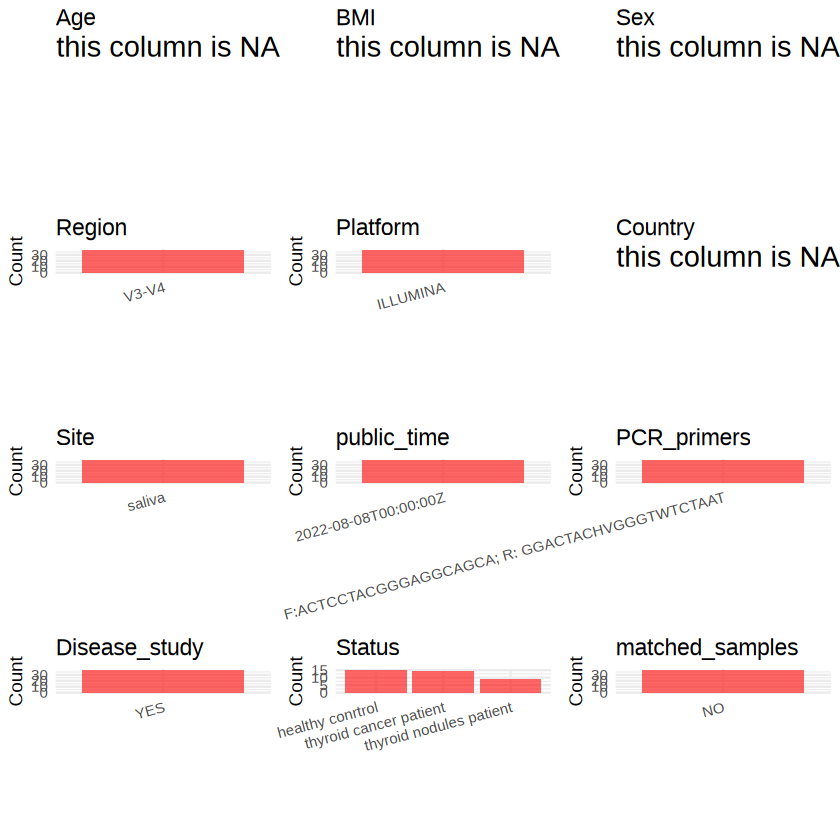

In [7]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [8]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-10/PRJNA863466/metadata.csv", quote = T)